In [35]:
#unzipping the dataset and images
!unzip -oq /content/paintings.zip -d /content/paintings

from pathlib import Path
import pandas as pd

folder = Path("/content/paintings")
image_dir = folder / "images"
paintings = pd.read_csv(folder / "metadata_balanced.csv")

#checking total painting numbers, paintings per group
print("Total paintings:", len(paintings))
print("\nPaintings per century:")
print(paintings["century"].value_counts().sort_index())

#checking if any missing
missing = [
    filename for filename in paintings["filename"]
    if not (folder / filename).is_file()
]

print("Missing images:", len(missing))
print("First image path:", folder / paintings["filename"].iloc[0])

Total paintings: 200

Paintings per century:
century
17    67
18    66
19    67
Name: count, dtype: int64
Missing images: 0
First image path: /content/paintings/images/436145.jpg


In [36]:
#splitting into test and training sets
from sklearn.model_selection import train_test_split

train, test = train_test_split(
    paintings,
    test_size=0.20,
    stratify=paintings["century"],
    random_state=42,
)
#training split number
print(f"Training: {len(train)} paintings")
print(train["century"].value_counts().sort_index())

#test split number
print(f"\nTest: {len(test)} paintings")
print(test["century"].value_counts().sort_index())

Training: 160 paintings
century
17    53
18    53
19    54
Name: count, dtype: int64

Test: 40 paintings
century
17    14
18    13
19    13
Name: count, dtype: int64


In [37]:
# extracting with ResNet-18
#pytorch and resnet
import numpy as np
import torch
from PIL import Image
from torchvision import transforms
from torchvision.models import ResNet18_Weights, resnet18
from tqdm.auto import tqdm

# AI assistance: I used ChatGPT to help write and explain
# this section of code. I ran it in Colab and checked the output.

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

resnet = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
resnet.fc = torch.nn.Identity()
resnet = resnet.to(device).eval()

#preprocessing size for resnet
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
])

#feature extraction
def extract_features(rows, description):
    features = []
    with torch.inference_mode():
        for filename in tqdm(rows["filename"], desc=description):
            with Image.open(folder / filename) as image:
                tensor = preprocess(image.convert("RGB")).unsqueeze(0)
            vector = resnet(tensor.to(device))
            features.append(vector.squeeze(0).cpu().numpy())
    return np.stack(features)

#train test split running through restnet features
X_train = extract_features(train, "Training paintings")
X_test = extract_features(test, "Test paintings")

y_train = train["century"]
y_test = test["century"]

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

Training paintings:   0%|          | 0/160 [00:00<?, ?it/s]

Test paintings:   0%|          | 0/40 [00:00<?, ?it/s]

Training features: (160, 512)
Test features: (40, 512)


In [38]:
# training logistic regression model - learning from 512 ResNet features to create the model that associates the features with known century labels
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

# model prediction
predictions = model.predict(X_test)

print("Number of test predictions:", len(predictions))
print("First 5 predicted centuries:", predictions[:5])

Number of test predictions: 40
First 5 predicted centuries: [17 18 17 18 17]


In [39]:
#comparing test accuracy
from sklearn.metrics import accuracy_score

#baseline accuracy from assuming 19th century for every test painting. 13/40 paintings are from 19th century so accuracy of 32.5% at baseline.
baseline_century = y_train.mode().iloc[0]
baseline_predictions = [baseline_century] * len(y_test)

model_accuracy = accuracy_score(y_test, predictions)
baseline_accuracy = accuracy_score(y_test, baseline_predictions)
improvement = 100 * (model_accuracy - baseline_accuracy)

#printing model accuracy vs baseline accuracy
print(f"Model accuracy: {model_accuracy:.1%}")
print(f"Baseline accuracy: {baseline_accuracy:.1%}")
print(f"Difference: {improvement:+.1f} percentage points")

Model accuracy: 60.0%
Baseline accuracy: 32.5%
Difference: +27.5 percentage points


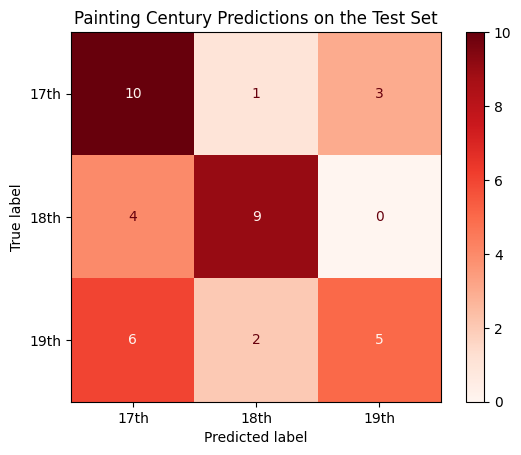

[[10  1  3]
 [ 4  9  0]
 [ 6  2  5]]


In [40]:
#confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

#format confusion matrix and display
display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    labels=[17, 18, 19],
    display_labels=["17th", "18th", "19th"],
    cmap="Reds",
)

display.ax_.set_title("Painting Century Predictions on the Test Set")
display.figure_.savefig(
    "/content/confusion_matrix.png", dpi=200, bbox_inches="tight"
)
plt.show()

print(display.confusion_matrix)

# confusion matrix showing that the model was best at predicting the 17th century paintings.
# most inconsistent  with 19th-century paintings, misclassifying 6 of 13 as 17th century.

In [41]:
# checking if grouping by artist changes the accuracy of the model

#checking artists common in both test and training sets
train_artists = set(train["artist"].dropna().str.strip().str.casefold()) - {""}
test_artists = set(test["artist"].dropna().str.strip().str.casefold()) - {""}

shared_artists = train_artists & test_artists
print("Artist labels in both sets:", len(shared_artists))
print(sorted(shared_artists))

Artist labels in both sets: 14
['angelica kauffmann', 'anthony van dyck', 'camille corot', 'edgar degas', 'edouard manet', 'el greco (domenikos theotokopoulos)', 'francesco guardi', 'françois boucher', 'giovanni benedetto castiglione (il grechetto)', 'gustave courbet', 'jean honoré fragonard', 'john constable', 'michiel jansz. van mierevelt', 'rembrandt']


In [42]:
from sklearn.model_selection import StratifiedGroupKFold

# standardize artist names so capitalization and spacing don't create separate groups.
artist_groups = (
    paintings["artist"]
    .fillna("")
    .str.strip()
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
    .replace("", "[missing artist]")
)

centuries = paintings["century"]
target_counts = centuries.value_counts() * 0.20

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
splits = list(splitter.split(paintings, centuries, groups=artist_groups))

def distance_from_target(split):
    _, test_idx = split
    counts = centuries.iloc[test_idx].value_counts()
    counts = counts.reindex(target_counts.index, fill_value=0)
    return (counts - target_counts).abs().sum()

train_idx, test_idx = min(splits, key=distance_from_target)
artist_train = paintings.iloc[train_idx].copy()
artist_test = paintings.iloc[test_idx].copy()

shared = set(artist_groups.iloc[train_idx]) & set(artist_groups.iloc[test_idx])

#test and training sets for paintings. with shared artists
print(f"Training: {len(artist_train)} paintings")
print(artist_train["century"].value_counts().sort_index())

print(f"\nTest: {len(artist_test)} paintings")
print(artist_test["century"].value_counts().sort_index())

print(f"\nShared artist labels: {len(shared)}")

Training: 157 paintings
century
17    52
18    51
19    54
Name: count, dtype: int64

Test: 43 paintings
century
17    15
18    15
19    13
Name: count, dtype: int64

Shared artist labels: 0


In [43]:
# matching the existing ResNet-18 features to each painting's original row index.
features_by_row = pd.DataFrame(
    np.vstack([X_train, X_test]),
    index=train.index.append(test.index),
)

X_artist_train = features_by_row.loc[artist_train.index].to_numpy()
X_artist_test = features_by_row.loc[artist_test.index].to_numpy()
y_artist_train = artist_train["century"]
y_artist_test = artist_test["century"]

# fitting using only the artist-grouped training set.
artist_model = LogisticRegression(max_iter=2000)
artist_model.fit(X_artist_train, y_artist_train)
artist_predictions = artist_model.predict(X_artist_test)

# recalculating the majority-century baseline for this split.
artist_baseline_century = y_artist_train.mode().iloc[0]
artist_baseline_predictions = [artist_baseline_century] * len(y_artist_test)

artist_accuracy = accuracy_score(y_artist_test, artist_predictions)
artist_baseline_accuracy = accuracy_score(
    y_artist_test, artist_baseline_predictions
)

print(f"Artist-grouped model accuracy: {artist_accuracy:.1%}")
print(f"Artist-grouped baseline accuracy: {artist_baseline_accuracy:.1%}")
print(f"Improvement: {100 * (artist_accuracy - artist_baseline_accuracy):+.1f} percentage points")

#accuracy is around 10% lower than without the artist splits.

Artist-grouped model accuracy: 51.2%
Artist-grouped baseline accuracy: 30.2%
Improvement: +20.9 percentage points


In [44]:
# cross validation for the artist groups
# AI assistance: I used ChatGPT to help write and explain
# this section of code. I ran it in Colab and checked the output.


from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline

# Keep artists together in each cross-validation fold.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
cv_artist_groups = artist_groups.loc[artist_train.index]

# Rank features and fit logistic regression inside each training fold.
pipeline = Pipeline([
    ("features", SelectKBest(score_func=f_classif)),
    ("model", LogisticRegression(max_iter=2000)),
])

search = GridSearchCV(
    pipeline,
    param_grid={"features__k": [32, 64, 128, 256, "all"]},
    scoring="accuracy",
    cv=cv,
)

search.fit(X_artist_train, y_artist_train, groups=cv_artist_groups)

for k, accuracy in zip(
    search.cv_results_["param_features__k"],
    search.cv_results_["mean_test_score"],
):
    print(f"Features: {k} | Mean validation accuracy: {accuracy:.1%}")

print("Best number of features:", search.best_params_["features__k"])

# In five-fold cross-validation by artist, logistic regression performed best with 64 ResNet-18 features,
# achieving 56.7% mean validation accuracy compared with 48.6% using all 512 features.

#interestingly, this requires less features for higher accuracy than without the artist groups.

Features: 32 | Mean validation accuracy: 53.2%
Features: 64 | Mean validation accuracy: 56.7%
Features: 128 | Mean validation accuracy: 51.7%
Features: 256 | Mean validation accuracy: 53.8%
Features: all | Mean validation accuracy: 48.6%
Best number of features: 64


In [45]:
# checking the accuracy of the model at different number of features (Cross validation)

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold

cv_no_groups = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search_no_groups = clone(search).set_params(cv=cv_no_groups)
search_no_groups.fit(X_artist_train, y_artist_train)

for k, score in zip(
    search_no_groups.cv_results_["param_features__k"],
    search_no_groups.cv_results_["mean_test_score"],
):
    print(f"Features: {k} | Mean validation accuracy: {score:.1%}")

print("Best number of features:", search_no_groups.best_params_["features__k"])
# best number is 128


Features: 32 | Mean validation accuracy: 57.9%
Features: 64 | Mean validation accuracy: 54.6%
Features: 128 | Mean validation accuracy: 58.5%
Features: 256 | Mean validation accuracy: 55.3%
Features: all | Mean validation accuracy: 55.3%
Best number of features: 128


In [46]:
from pathlib import Path
import pandas as pd

output_folder = Path("/content/OUTPUT")
output_folder.mkdir(exist_ok=True)

# 1. Compare model and baseline accuracy on the two held-out test sets.
test_results = pd.DataFrame({
    "test_split": ["Painting-level", "Artist-grouped"],
    "test_paintings": [len(y_test), len(y_artist_test)],
    "model_accuracy_pct": [100 * model_accuracy, 100 * artist_accuracy],
    "baseline_accuracy_pct": [
        100 * baseline_accuracy,
        100 * artist_baseline_accuracy,
    ],
})
test_results["improvement_percentage_points"] = (
    test_results["model_accuracy_pct"] - test_results["baseline_accuracy_pct"]
)
test_results = test_results.round(1)
test_results.to_csv(output_folder / "test_accuracy_comparison.csv", index=False)

# 2. Save the mean validation accuracy for every feature count tested.
cv_rows = []
for method, result in [
    ("Artist-grouped", search),
    ("Ungrouped", search_no_groups),
]:
    scores = result.cv_results_
    for k, score in zip(
        scores["param_features__k"], scores["mean_test_score"]
    ):
        cv_rows.append({
            "cv_method": method,
            "resnet_features": 512 if k == "all" else int(k),
            "mean_validation_accuracy_pct": round(100 * score, 1),
            "best_feature_count": k == result.best_params_["features__k"],
        })

cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(output_folder / "feature_selection_cv_results.csv", index=False)
from IPython.display import display as show_table

show_table(test_results)
show_table(cv_results)

,test_split,test_paintings,model_accuracy_pct,baseline_accuracy_pct,improvement_percentage_points
0,Painting-level,40,60.0,32.5,27.5
1,Artist-grouped,43,51.2,30.2,20.9


,cv_method,resnet_features,mean_validation_accuracy_pct,best_feature_count
0,Artist-grouped,32,53.2,False
1,Artist-grouped,64,56.7,True
2,Artist-grouped,128,51.7,False
3,Artist-grouped,256,53.8,False
4,Artist-grouped,512,48.6,False
5,Ungrouped,32,57.9,False
6,Ungrouped,64,54.6,False
7,Ungrouped,128,58.5,True
8,Ungrouped,256,55.3,False
9,Ungrouped,512,55.3,False
